In [3]:
# Load packages
import os 
from matplotlib import pyplot as plt
import os
import numpy as np
from IPython.display import display
import pandas as pd
import seaborn as sns
from PIL import Image
import json
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from skimage.filters import threshold_otsu
import copy
import pickle

cm = sns.color_palette("crest", as_cmap=True)
cm_inv = sns.cubehelix_palette(start=.5, rot=-.75, reverse=True, as_cmap=True)

In [ ]:
# Graph class (not used, for bkp)
class Graph(dict):
    def __init__(self, graph):
        super().__init__(graph)

    def normalize_graph(self):
        # Compute max value for normalization
        max_vals = self['node0']['feats'].copy()
        for node in range(self['num_nodes']):
            feats = self[f'node{node}']['feats']
            for i,f in enumerate(feats):
                if f > max_vals[i]:
                    max_vals[i] = f
        # Normalize each feature to [0,1] with a max normalization
        for node in range(self['num_nodes']):
            feats = self[f'node{node}']['feats']
            for i,f in enumerate(feats):
                if max_vals[i] > 0:
                    feats[i] = f / max_vals[i]
                else:
                    feats[i] = 0.0
            self[f'node{node}']['feats'] = feats

    def compute_otsu_threshold(self):
        feats = [[] for _ in range(self['num_feats'])]
        for node in range(self['num_nodes']):
            node_feats = self[f'node{node}']['feats']
            for i, f in enumerate(node_feats):
                feats[i].append(f)
        threshs = [threshold_otsu(np.array(f)) for f in feats]
        return threshs

    def sum_value(self, values : list, func_condition = lambda x, y: x > y):
        for node in range(self['num_nodes']):
            feats = [feat + val if func_condition(feat, val) else feat for feat,val in zip(self[f'node{node}']['feats'],values)]
            self[f'node{node}']['feats'] = feats

    def upsample_graph(self, node_map, kernel_map, graph_increased):
        """
        Upsample the graph_target to the size of graph_increased using the node_map and kernel_map
        
        Args:
            graph_target (dict): The target graph to be upsampled
            node_map (list): The mapping of nodes from graph_increased to graph_target
            kernel_map (list): The mapping of kernels from graph_increased to graph_target
            graph_increased (dict): The graph with increased number of nodes and kernels
        """
        graph = copy.deepcopy(graph_increased)
        for node in range(graph['num_nodes']):
            feats_target = self[f'node{node_map[node]}']['feats']
            graph[f'node{node}']['feats'] = [feats_target[kernel_map[k]] for k in range(graph['num_feats'])]

        return graph

    def visualize_activations(self, spx_img, channels, img_name):
        # convert each feature channel of the merged graph into an image using the superpixel image of the first scale (10000)
        num_kernels = len(channels)

        # visualize as a grid of images
        ncols = 4
        nrows = num_kernels // ncols + (num_kernels % ncols)
        if nrows < 2:
            nrows = 2
        
        fig, axes = plt.subplots(nrows, ncols, figsize=(5*ncols, 5*nrows))
        for i,k in enumerate(channels):

            # normalize values in the graph to [0,255]
            min_val, max_val = self[f'node{0}']['feats'][k], self[f'node{0}']['feats'][k]
            feats = np.zeros(self['num_nodes'])
            for node_id in range(0,self['num_nodes']):
                value = self[f'node{node_id}']['feats'][k]
                min_val = min(min_val, value)
                max_val = max(max_val, value)
                feats[node_id] = value
            feats = (feats - min_val) / (max_val - min_val) * 255

            # create an image where each pixel is assigned the activation value of its superpixel
            feat_img = np.zeros((spx_img.shape[0] * spx_img.shape[1]))
            for j,p in enumerate(spx_img.flatten()):
                feat_img[j] = int(feats[p-1])

            feat_img = feat_img.reshape(spx_img.shape[0], spx_img.shape[1]).astype(np.uint8)
            #feat_img = np.stack([feat_img, feat_img, feat_img], axis=-1)

            # save feat_img as a png
            #Image.fromarray(feat_img).save(f'/home/isabela/Codes/{img_name}_kernel_{k}_merged.png')

            axes[i // ncols, i % ncols].imshow(feat_img, cmap='gray')
            axes[i // ncols, i % ncols].set_title(f'Kernel {k}')
            axes[i // ncols, i % ncols].axis('off')
        plt.tight_layout()
        #plt.show()
        fig.savefig(f'/home/isabela/Codes/{img_name}.png')


In [15]:
def read_img(img_path, spx_img=False):
    img = Image.open(img_path)
    if spx_img:
        img = img.convert("I;16")
        img = np.array(img)
        replace = np.unique(img)
        for p in range(len(replace)):
            img[img == replace[p]] = p + 1
    else:
        img = np.array(img)
    return img

def read_graph(graph_path):
    with open(graph_path, 'r') as f:
        graph = json.load(f)
    return graph

def normalize_graph(graph):
    # Compute max value for normalization
    max_vals = graph['node0']['feats'].copy()
    for node in range(graph['num_nodes']):
        feats = graph[f'node{node}']['feats']
        for i,f in enumerate(feats):
            if f > max_vals[i]:
                max_vals[i] = f
    # Normalize each feature to [0,1] with a max normalization
    for node in range(graph['num_nodes']):
        feats = graph[f'node{node}']['feats']
        for i,f in enumerate(feats):
            if max_vals[i] > 0:
                feats[i] = f / max_vals[i]
            else:
                feats[i] = 0.0
        graph[f'node{node}']['feats'] = feats

def compute_mean_std(graphs, kernels_maps, node_maps):
    # compute the mean and std per node and channel across multiple graphs
    num_nodes0 = graphs[0]['num_nodes']
    num_feats0 = graphs[0]['num_feats']
    means = np.zeros((num_nodes0, num_feats0))
    stds = np.zeros((num_nodes0, num_feats0))
    for node in range(num_nodes0):
        for channel in range(num_feats0):
            values = [graphs[0][f'node{node}']['feats'][channel]]
            for scale, graph in enumerate(graphs[1::]):
                values.append(graph[f'node{node_maps[scale][node]}']['feats'][kernels_maps[scale][channel]])
            means[node, channel] = np.mean(values)
            stds[node, channel] = np.std(values)
    return means, stds

def compute_mean_std_featMatrix(feature_matrices, kernels_maps, node_maps):
    # compute the mean and std per node and channel across multiple feature matrices
    num_nodes0, num_feats0 = feature_matrices[0].shape
    means = np.zeros((num_nodes0, num_feats0))
    stds = np.zeros((num_nodes0, num_feats0))
    for node in range(num_nodes0):
        for channel in range(num_feats0):
            values = [feature_matrices[0][node, channel]]
            for scale, fm in enumerate(feature_matrices[1::]):
                values.append(fm[node_maps[scale][node], kernels_maps[scale][channel]])
            means[node, channel] = np.mean(values)
            stds[node, channel] = np.std(values)
    return means, stds

def graph_to_featMatrix(graph):
    feat_matrix = np.zeros((graph['num_nodes'], graph['num_feats']))
    for node in range(graph['num_nodes']):
        feat_matrix[node,:] = np.array(graph[f'node{node}']['feats'])
    return feat_matrix

def compute_otsu_threshold(feat_matrix):
    # transform the cols in feat_matrix into vectors
    feats = [feat_matrix[:, i] for i in range(feat_matrix.shape[1])]
    threshs = [threshold_otsu(f) for f in feats]
    return threshs

class FeatureMatrix(np.ndarray):
    def __new__(cls, feat_matrix):
        obj = np.array(feat_matrix).view(cls)
        return obj

    def __init__(self, feat_matrix):
        # No need to call super().__init__ or initialize anything here
        pass

    def normalize(self):
        # Compute max value per column for normalization
        max_vals = np.max(self, axis=0) 
        # Normalize each feature to [0,1] with a max normalization
        for i in range(self.shape[1]):
            if max_vals[i] > 0:
                self[:,i] = self[:,i] / max_vals[i]
            else:
                self[:,i] = 0.0
        return self

    def compute_otsu_threshold(self):
        # transform the cols in feat_matrix into vectors
        feats = [self[:, i] for i in range(self.shape[1])]
        threshs = [threshold_otsu(f) for f in feats]
        return threshs

    def sum_value(self, values : list, func_condition = lambda x, y: x > y):
        sum_matrix = np.zeros(self.shape)
        for i, val in enumerate(values):
            sum_matrix[:,i] = np.array([val if func_condition(f, val) else 0 for f in self[:,i]])
        return self+sum_matrix
    
    def upsample_featMatrix(self, node_map, kernel_map, feat_matrix_increased):
        """
        Upsample the feat_matrix_target to the size of feat_matrix_increased using the node_map and kernel_map
        
        Args:
            feat_matrix_target (np.ndarray): The target feature matrix to be upsampled
            node_map (list): The mapping of nodes from feat_matrix_increased to feat_matrix_target
            kernel_map (list): The mapping of kernels from feat_matrix_increased to feat_matrix_target
            feat_matrix_increased (np.ndarray): The feature matrix with increased number of nodes and kernels
        """
        feat_matrix = np.zeros(feat_matrix_increased.shape)
        for node in range(feat_matrix_increased.shape[0]):
            feats_target = self[node_map[node], :]
            feat_matrix[node, :] = np.array([feats_target[kernel_map[k]] for k in range(feat_matrix_increased.shape[1])])
        return FeatureMatrix(feat_matrix)

    def apply_sigmoid(self, gain=1.0, cutoff=0):
        # apply sigmoid to reach column
        self[:] = 1 / (1 + np.exp(-gain * (self - cutoff)))
        return self

    def visualize_activations(self, spx_img, channels, img_name):
        # convert each feature channel of the merged graph into an image using the superpixel image of the first scale (10000)
        num_kernels = len(channels)

        # visualize as a grid of images
        ncols = 4
        nrows = num_kernels // ncols + (num_kernels % ncols)
        if nrows < 2:
            nrows = 2
        
        fig, axes = plt.subplots(nrows, ncols, figsize=(5*ncols, 5*nrows))
        for i,k in enumerate(channels):

            # normalize values in the graph to [0,255]
            feats = self[:, k].copy() # copy the k-th column into a vector
            min_val = np.min(feats)
            max_val = np.max(feats)
            feats = (feats - min_val) / (max_val - min_val) * 255

            # create an image where each pixel is assigned the activation value of its superpixel
            feat_img = np.zeros((spx_img.shape[0] * spx_img.shape[1]))
            for j,p in enumerate(spx_img.flatten()):
                feat_img[j] = int(feats[p-1])

            feat_img = feat_img.reshape(spx_img.shape[0], spx_img.shape[1]).astype(np.uint8)
            #feat_img = np.stack([feat_img, feat_img, feat_img], axis=-1)
            #Image.fromarray(feat_img).save(f'/home/isabela/Codes/{img_name}_kernel_{k}_merged.png') # save feat_img as a png

            axes[i // ncols, i % ncols].imshow(feat_img, cmap='gray')
            axes[i // ncols, i % ncols].set_title(f'Kernel {k}')
            axes[i // ncols, i % ncols].axis('off')
        plt.tight_layout()
        #plt.show()
        fig.savefig(f'/home/isabela/Codes/{img_name}.png')


In [ ]:
def merge_scales_v1(graphs, node_maps, kernels_maps, node_sizes):
    """ merge scales with a dot product

    This solution works well when the object activation is stronger than the background activation.
    However, when there are several objects with different intensities, 
    the dot product with further min-max normalization may favor only objects with higher intensities, 
    while objects with lower intensities may be lost.
    """

    merged_graph = copy.deepcopy(graphs[0]) # start with the graph of the first scale (10000)
    for scale in range(len(graphs) - 1):
        graph_i = copy.deepcopy(graphs[scale + 1]) # next scale graph
        node_map = node_maps[scale] # node map from a finer scale to a coarser scale
        kernel_map_i = kernels_maps[scale] # feature channels to merge
        
        for node_id in range(merged_graph['num_nodes']):
            node_i = node_map[node_id]
            feats_i = np.array(graph_i[f'node{node_i}']['feats'])
            for i,k in enumerate(kernel_map_i):
                merged_graph[f'node{node_id}']['feats'][i] *= feats_i[k]

    return merged_graph

def merge_scales_dotProd(feature_matrices, node_maps, kernels_maps, thresh=False, std=False):
    """ merge scales with a dot product

    This solution works well when the object activation is stronger than the background activation.
    However, when there are several objects with different intensities, 
    the dot product with further min-max normalization may favor only objects with higher intensities, 
    while objects with lower intensities may be lost.
    """

    merged_features = copy.deepcopy(feature_matrices[0]) # start with the graph of the first scale (largest number of nodes)

    if thresh:
        thresholds = compute_otsu_threshold(merged_features)
        merged_features = merged_features.sum_value(thresholds)

    for i, fm in enumerate(feature_matrices[1::]):
        fm = fm.upsample_featMatrix(node_maps[i], kernels_maps[i], feature_matrices[0])
        if thresh:
            thresholds = compute_otsu_threshold(fm)
            fm = fm.sum_value(thresholds)
        merged_features *= fm
    
    if std:
        __, stds = compute_mean_std_featMatrix(feature_matrices, kernels_maps, node_maps)
        for i in range(merged_features.shape[0]):
            merged_features[i, :] *= (1 - stds[i, :])

    return merged_features

def merge_scales_v2(graphs, node_maps, kernels_maps, node_sizes):
    """ 
    The idea here is to preserve redundant information across scales with similar intensities. 
    Therefore, for regions with approximately x activation at all scales should have approximately x activation in the merged graph.
    And for varying intensities across scales, the resulting activation should be smaller even if one of the magnitudes is high.
    """

    # For [0.1, 0.5, 0.7, 0.9] , [0.1, 0.5, 0.7, 0.9], and [0.1, 0.5, 0.7, 0.9], the result should be [0.1, 0.5, 0.7, 0.9]
     # std = 0, 0, 0, 0
     # mean = 0.1, 0.5, 0.7, 0.9
     # mean - std = 0.1, 0.5, 0.7, 0.9
     # dot product = 0.001, 0.125, 0.343, 0.729

     # For [0.1, 0.5, 0.7, 0.9] , [0.1, 0.1, 0.6, 0.3] , [0.1, 0.9, 0.8, 0.1]
     # std = 0, 0.4, 0.1, 0.416333
     # mean = 0.1, 0.5, 0.7, 0.433333
     # mean - std = 0.1, 0.1, 0.6, 0.016667
     # dot product = 0.001, 0.045, 0.336, 0.027

    # dot product with thresholding
    
    merged_graph = copy.deepcopy(graphs[0]) # start with the graph of the first scale (10000)
    # compute the otsu threshold for each feature channel in the next scale graph
    threshs = merged_graph.compute_otsu_threshold()
    merged_graph = merged_graph.sum_value(threshs)

    for scale in range(len(graphs) - 1):
        graph_i = copy.deepcopy(graphs[scale + 1]) # next scale graph
        node_map = node_maps[scale] # node map from a finer scale to a coarser scale
        kernel_map_i = kernels_maps[scale] # feature channels to merge
        
        # compute the otsu threshold for each feature channel in the next scale graph
        threshs = graph_i.compute_otsu_threshold()
        graph_i = graph_i.sum_value(threshs)

        for node_id in range(merged_graph['num_nodes']):
            node_i = node_map[node_id]
            feats_i = np.array(graph_i[f'node{node_i}']['feats'])
            for i,k in enumerate(kernel_map_i):
                merged_graph[f'node{node_id}']['feats'][i] *= feats_i[k]

    return merged_graph


def merge_scales_meanStd(feature_matrices, node_maps, kernels_maps, node_sizes):
    """ 
    The idea here is to preserve redundant information across scales with similar intensities. 
    Therefore, for regions with approximately x activation at all scales should have approximately x activation in the merged graph.
    And for varying intensities across scales, the resulting activation should be smaller even if one of the magnitudes is high.
    """
    # mean - std
    # The data is normalized to [0,1] at each scale.
    # Then, the mean and std ranges are also in [0,1].
    # So, std > mean is not possible.

    means, stds = compute_mean_std_featMatrix(feature_matrices, kernels_maps, node_maps)
    merged_features = copy.deepcopy(feature_matrices[0]) # start with the graph of the first scale (10000)

    for i in range(merged_features.shape[0]):
        merged_features[i, :] = (means[i, :] - stds[i, :])

    thresholds = compute_otsu_threshold(merged_features)
    # apply the threshold to the merged features
    for i in range(merged_features.shape[1]):
        merged_features[:, i] = np.array([val if val >= thresholds[i] else 0 for val in merged_features[:, i]])

    return merged_features

def merge_scales_sum(feature_matrices, node_maps, kernels_maps):
   
    merged_features = copy.deepcopy(feature_matrices[0]) # start with the graph of the first scale (10000)
    for i, fm in enumerate(feature_matrices[1::]):
        fm = fm.upsample_featMatrix(node_maps[i], kernels_maps[i], feature_matrices[0])
        merged_features += fm
    return merged_features



Read the graphs and superpixel images, and create superpixel maps from the first scale (finest) to the others.

In [6]:
def compute_node_maps(spx_imgs):
    # compute the node maps from a scale 0 to all other scales
    node_maps = []
    spx_img0 = spx_imgs[0].flatten()
    nnodes0 = spx_img0.max()
    for i in range(1, len(spx_imgs)):
        spx_img1 = spx_imgs[i].flatten()
        node_map = np.zeros(nnodes0, dtype=int)
        for j,p in enumerate(spx_img0):
            node_map[p - 1] = int(spx_img1[j] - 1)
        node_maps.append(node_map)
    return node_maps

def compute_kernels_maps(model_dir):
    # contruct a kernels map from a scale 0 to i+1
    kernels_maps = []
    with open(os.path.join(model_dir, 'model', 'kernels_map_1.txt'), 'r') as f:
        for _,line in enumerate(f.readlines()):
            kernels = line.strip().split(' ')
            kernels_map = [i for i in range(len(kernels))] # store a mapping of kernels from scale 0 (finer) to i+1 (coarser)
            counter = 0 # count the kernel indexes of scale i+1 (coarser scale)
            for i,k in enumerate(kernels):
                k = int(k)-1
                if k != i:
                    k2 = kernels_map[k]
                    kernels_map[i] = k2           
                else:
                    kernels_map[i] = counter
                    counter += 1

            kernels_maps.append(kernels_map)

    return kernels_maps

def get_data_dataset(img_names, spx_scales, model_dir):
    feature_matrices, spx_imgs, node_maps, bkg_kernels = {}, {}, {}, {}
    for img_name in img_names:

        feature_matrices_img, spx_imgs_img, node_maps_img = [], [], []

        for scale in spx_scales:

            # load superpixel image
            spx_path = os.path.join(model_dir, f'labels1_spx{scale}', f'{img_name}.pgm')
            spx_img = read_img(spx_path, spx_img=True)
            spx_imgs_img.append(spx_img)

            # load feature matrix
            feat_matrix_path = os.path.join(model_dir, f'layer1_spx{scale}', f'{img_name}.json')
            graph = read_graph(feat_matrix_path)
            normalize_graph(graph)
            feat_matrix = graph_to_featMatrix(graph)
            feature_matrices_img.append(feat_matrix)

            # compute node size for each superpixel images
            #node_sizes = []
            #for spx_img in spx_imgs:
            #    node_size = np.array([len(spx_img[spx_img == p]) for p in range(1,spx_img.max())])
            #    node_sizes.append(node_size)

        feature_matrices[img_name] = feature_matrices_img
        spx_imgs[img_name] = spx_imgs_img
        node_maps[img_name] = compute_node_maps(spx_imgs_img) # compute the node maps from a scale 0 to i+1

    return feature_matrices, spx_imgs, node_maps, bkg_kernels


In [ ]:
# load data and create data structures

# load data from cells dataset
model_dirs, obj_kernels, bkg_kernels, img_names, spx_scales, feature_matrices, spx_imgs, node_maps, kernels_maps = {},{}, {}, {}, {}, {}, {}, {}, {}

dataset = 'cells_dataset'
model_dirs[dataset] = '/home/isabela/Codes/LibIFT/Results/cells_dataset/split5/interactive_markers/arch_cells4/gflim-BoFP-multiscale/graph-based/SH/60000-40000-20000-10000/kmeans/SUM-NONE'
obj_kernels[dataset] = [3,6,14,15]
img_names[dataset] = ['6', '10']
spx_scales[dataset] = ['60000', '40000', '20000', '10000']

# contruct a kernels map from a scale 0 to i+1
kernels_maps[dataset] = compute_kernels_maps(model_dirs[dataset])

feature_matrices[dataset], spx_imgs[dataset], node_maps[dataset], bkg_kernels[dataset] = get_data_dataset(img_names[dataset], spx_scales[dataset], model_dirs[dataset])

num_kernels = feature_matrices[dataset][img_names[dataset][0]][0].shape[1]
bkg_kernels[dataset] = [k for k in range(num_kernels) if k not in obj_kernels]

# ----

dataset = 'schisto'
model_dirs[dataset] = '/home/isabela/Codes/LibIFT/Results/schisto/split1/interactive_markers/arch_schisto1/gflim-BoFP-multiscale/graph-based/SH/10000-8000-6000/kmeans/SUM-NONE/'
obj_kernels[dataset] = [10,11,12,13,24,25,26,27,28,29,30,31,32,33,73,74,75,76,77,120,121,122,123,124]
img_names[dataset] = ['000028', '000017', '000212']
spx_scales[dataset] = ['10000', '8000', '6000']

# contruct a kernels map from a scale 0 to i+1
kernels_maps[dataset] = compute_kernels_maps(model_dirs[dataset])

feature_matrices[dataset], spx_imgs[dataset], node_maps[dataset], bkg_kernels[dataset] = get_data_dataset(img_names[dataset], spx_scales[dataset], model_dirs[dataset])

num_kernels = feature_matrices[dataset][img_names[dataset][0]][0].shape[1]
bkg_kernels[dataset] = [k for k in range(num_kernels) if k not in obj_kernels]

In [ ]:
# save the data structure

path ='/home/isabela/Codes/multi-scale_results'

data = {
    'model_dirs' : model_dirs,
    'datasets': ['cells_dataset', 'schisto'],
}

for dataset in data['datasets']:
    data[dataset] = {
        'model_dir': model_dirs[dataset],
        'obj_kernels': obj_kernels[dataset],
        'bkg_kernels': bkg_kernels[dataset],
        'img_names': img_names[dataset],
        'spx_scales': spx_scales[dataset],
        'feature_matrices': feature_matrices[dataset],
        'spx_imgs': spx_imgs[dataset],
        'node_maps': node_maps[dataset],
        'kernels_maps': kernels_maps[dataset],
    }

file = open(os.path.join(path, 'data.pkl'), 'wb+')
pickle.dump(data, file)
file.close()

In [7]:
#reload object from file
path ='/home/isabela/Codes/multi-scale_results'
file = open(os.path.join(path, 'data.pkl'), 'rb+')
data = pickle.load(file)
file.close()

In [ ]:
# merge scales using dot product and save results
for dataset in data['datasets']:
    for img_name in data[dataset]['img_names']:
        feature_matrices = [FeatureMatrix(np.array(fm)) for fm in data[dataset]['feature_matrices'][img_name]]
        feat_matrix = merge_scales_dotProd(feature_matrices, data[dataset]['node_maps'][img_name], data[dataset]['kernels_maps'], std=True)
        feat_matrix.visualize_activations(data[dataset]['spx_imgs'][img_name][0], data[dataset]['obj_kernels'], f'{dataset}_{img_name}_obj_kernels_merged_dotProd_std')
        feat_matrix.visualize_activations(data[dataset]['spx_imgs'][img_name][0], data[dataset]['bkg_kernels'], f'{dataset}_{img_name}_bkg_kernels_merged_dotProd_std')

Merging scales for cells_dataset - 6 with thresholding
Merged Thresholds: 16
0 Thresholds: 16
1 Thresholds: 16
2 Thresholds: 16
Merging scales for cells_dataset - 10 with thresholding
Merged Thresholds: 16
0 Thresholds: 16
1 Thresholds: 16
2 Thresholds: 16
Merging scales for schisto - 000028 with thresholding
Merged Thresholds: 137
0 Thresholds: 137
1 Thresholds: 137
Merging scales for schisto - 000017 with thresholding
Merged Thresholds: 137
0 Thresholds: 137
1 Thresholds: 137
Merging scales for schisto - 000212 with thresholding
Merged Thresholds: 137
0 Thresholds: 137
1 Thresholds: 137


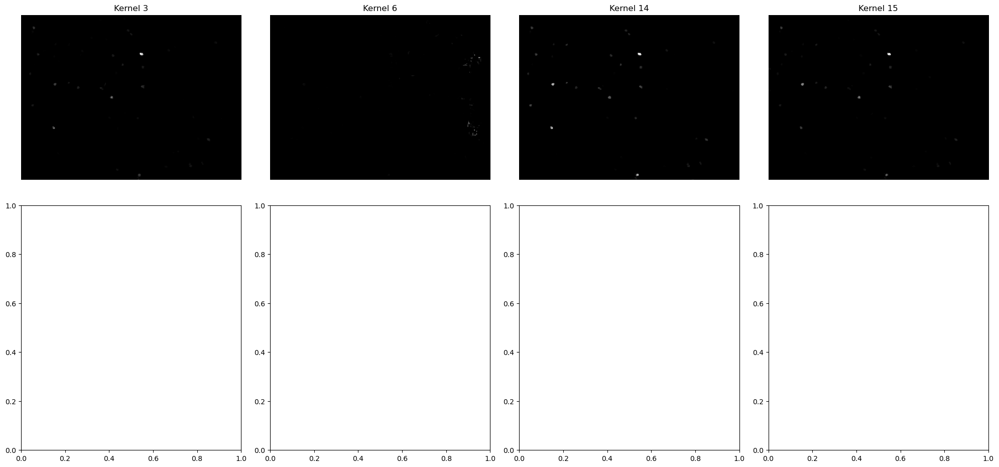

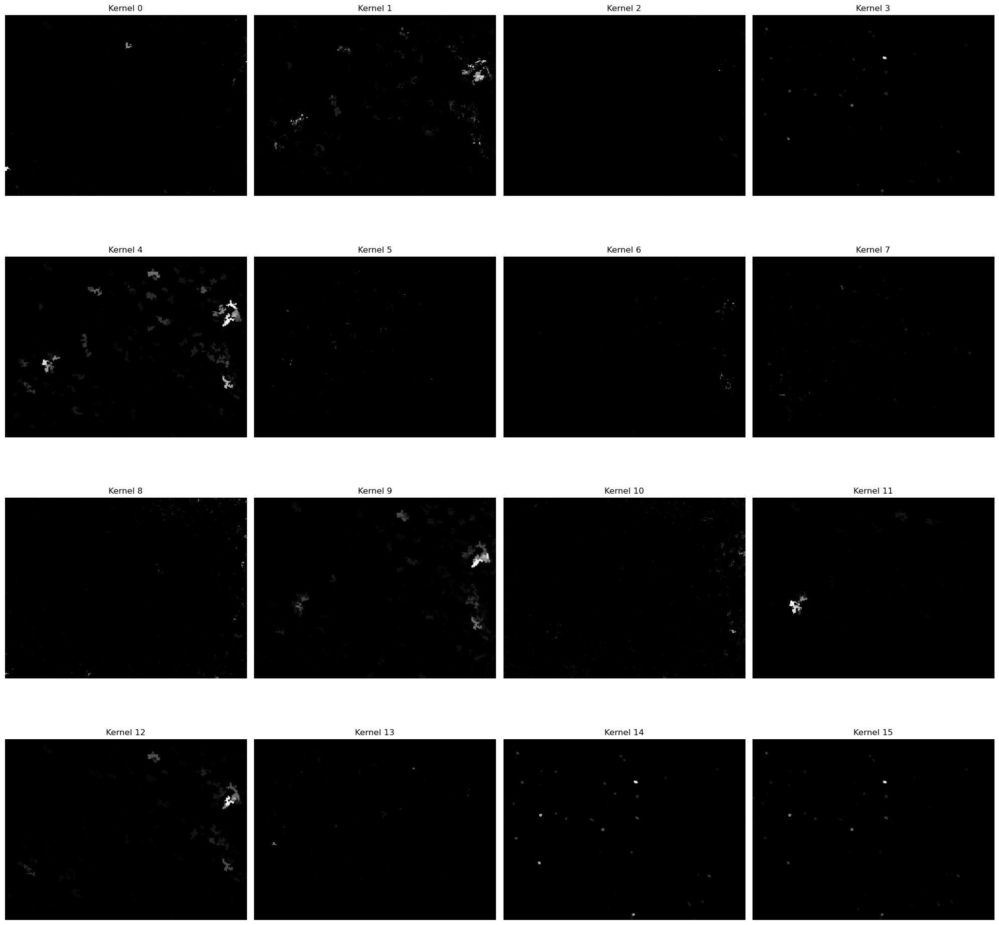

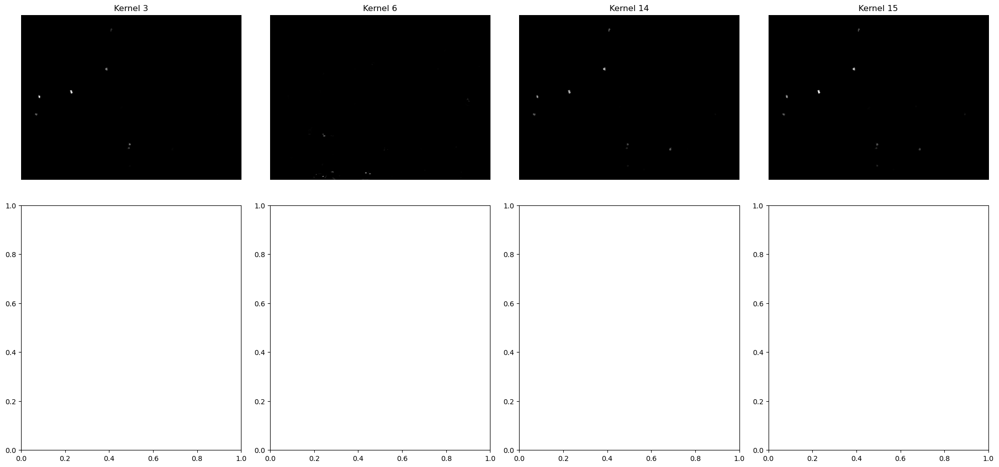

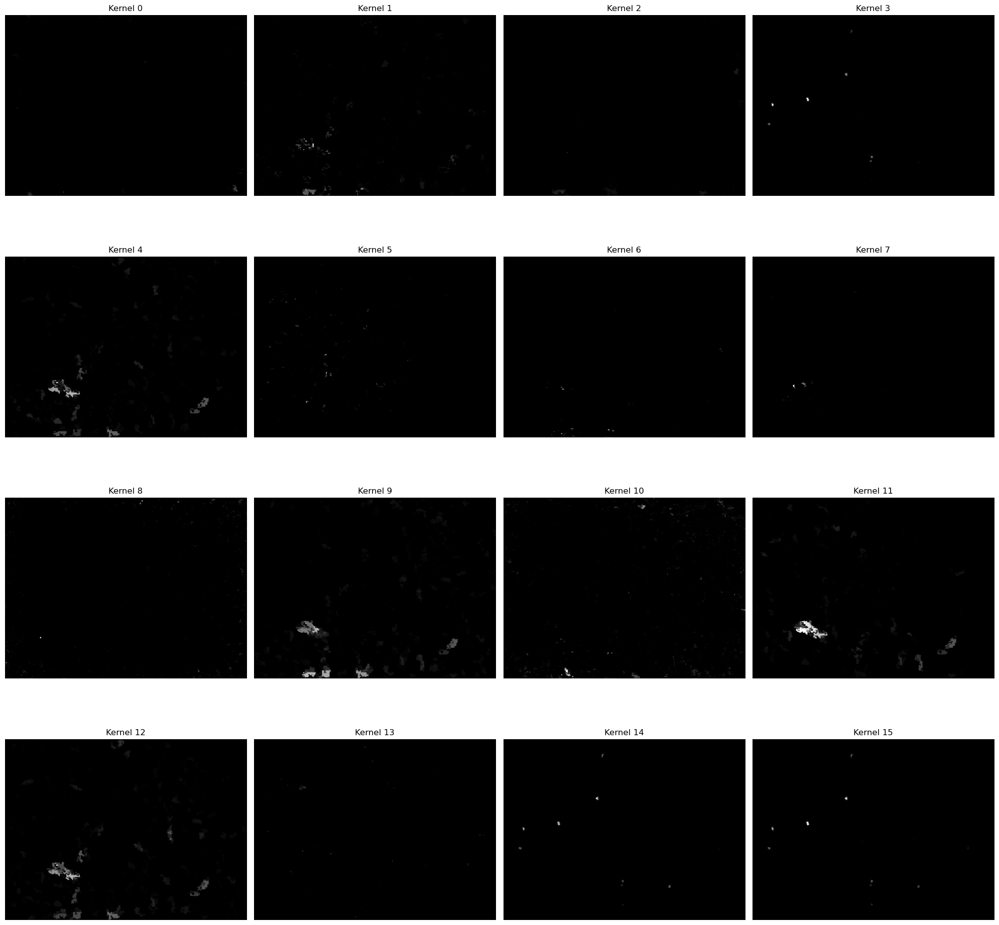

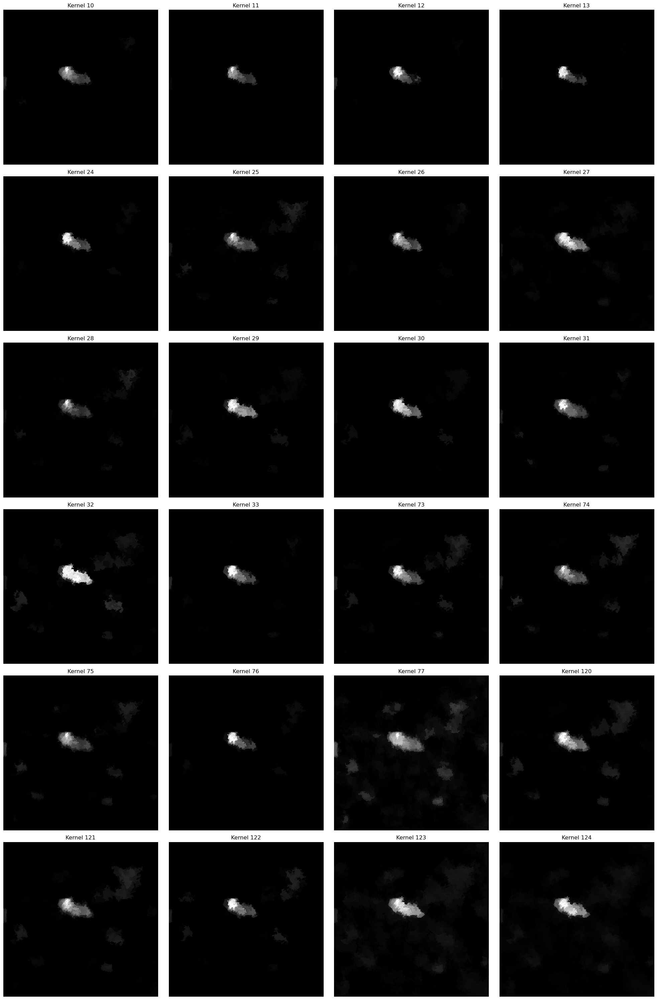




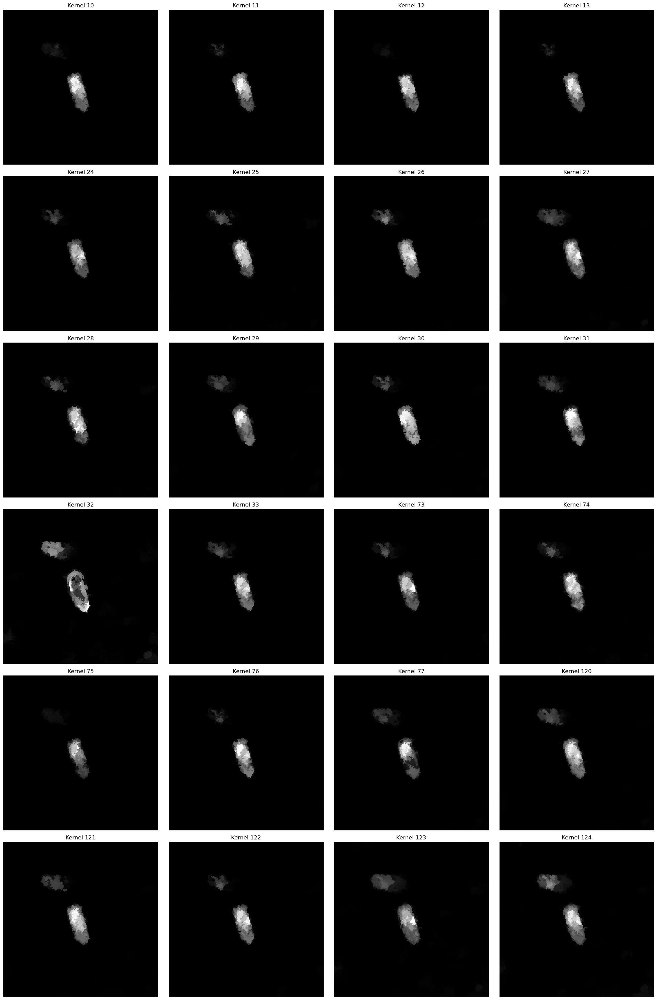




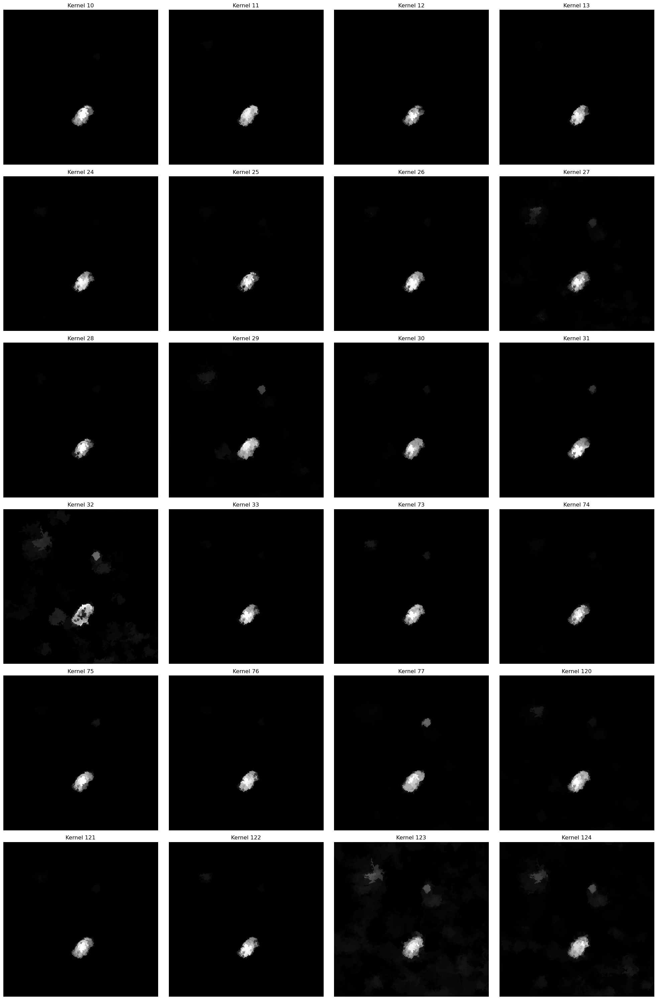




In [17]:
# merge scales using dot product and save results
for dataset in data['datasets']:
    for img_name in data[dataset]['img_names']:
        print(f'Merging scales for {dataset} - {img_name} with thresholding')
        feature_matrices = [FeatureMatrix(np.array(fm)) for fm in data[dataset]['feature_matrices'][img_name]]
        feat_matrix = merge_scales_dotProd(feature_matrices, data[dataset]['node_maps'][img_name], data[dataset]['kernels_maps'], thresh=True)
        feat_matrix.visualize_activations(data[dataset]['spx_imgs'][img_name][0], data[dataset]['obj_kernels'], f'{dataset}_{img_name}_obj_kernels_merged_dotProd_thresh')
        feat_matrix.visualize_activations(data[dataset]['spx_imgs'][img_name][0], data[dataset]['bkg_kernels'], f'{dataset}_{img_name}_bkg_kernels_merged_dotProd_thresh')

Merged Thresholds: 16
0 Thresholds: 16
1 Thresholds: 16
2 Thresholds: 16
Merged Thresholds: 16
0 Thresholds: 16
1 Thresholds: 16
2 Thresholds: 16
Merged Thresholds: 137
0 Thresholds: 137
1 Thresholds: 137
Merged Thresholds: 137
0 Thresholds: 137
1 Thresholds: 137
Merged Thresholds: 137
0 Thresholds: 137
1 Thresholds: 137


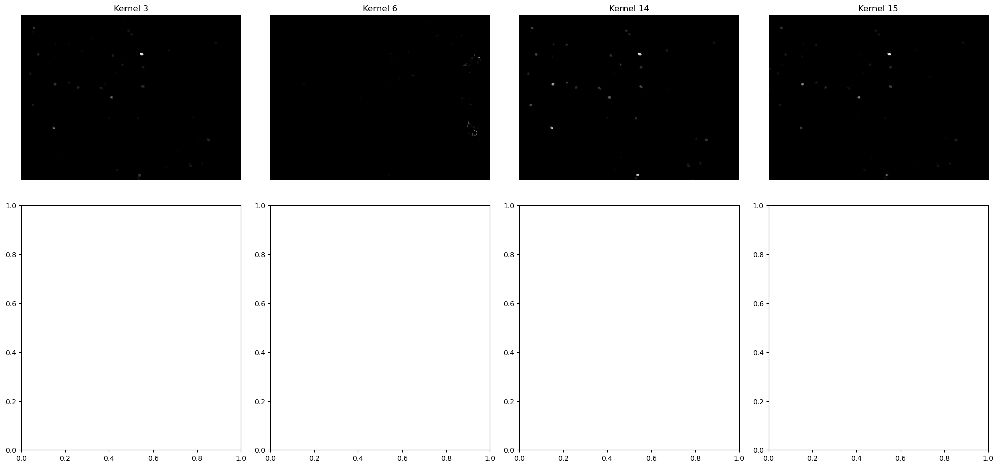

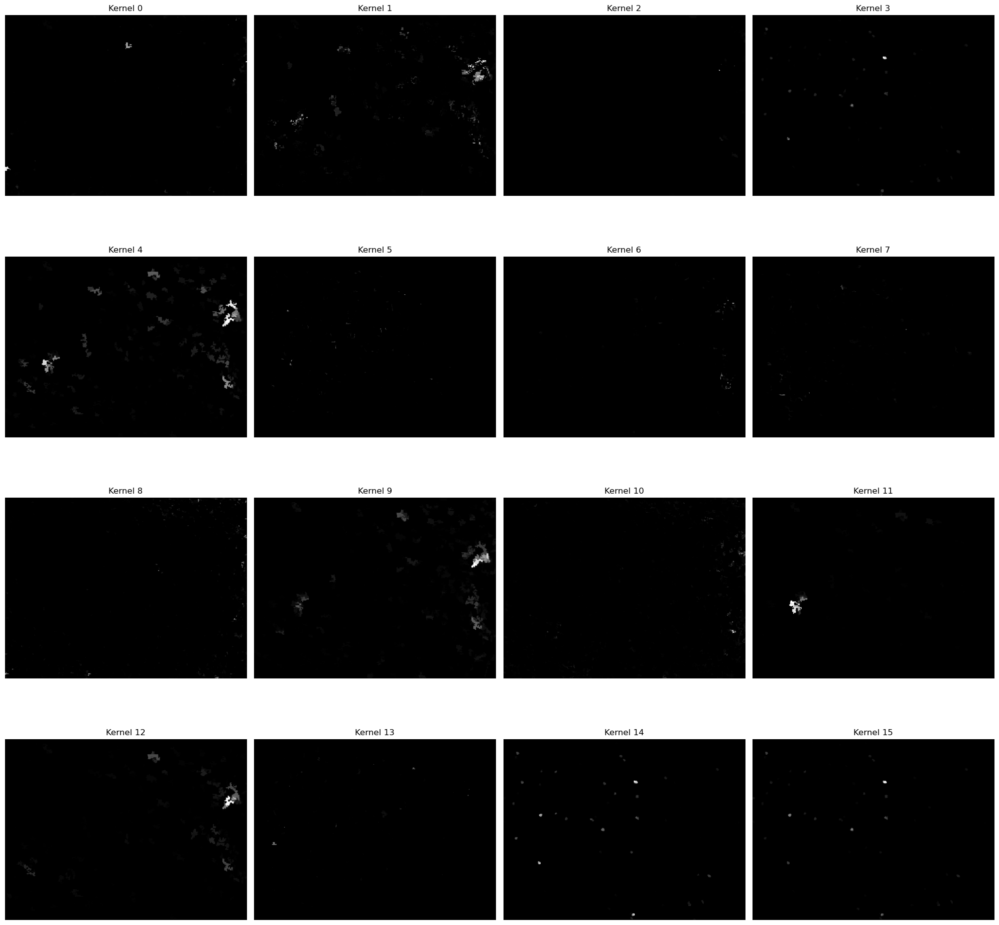

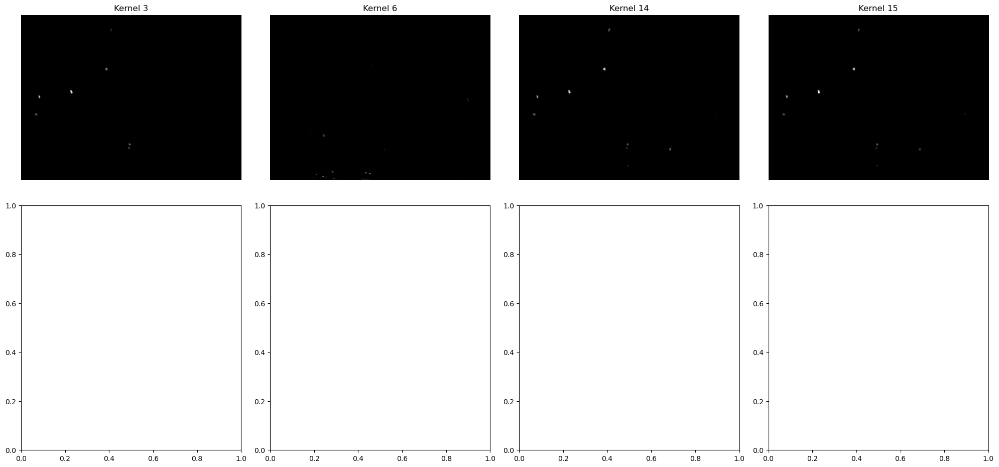

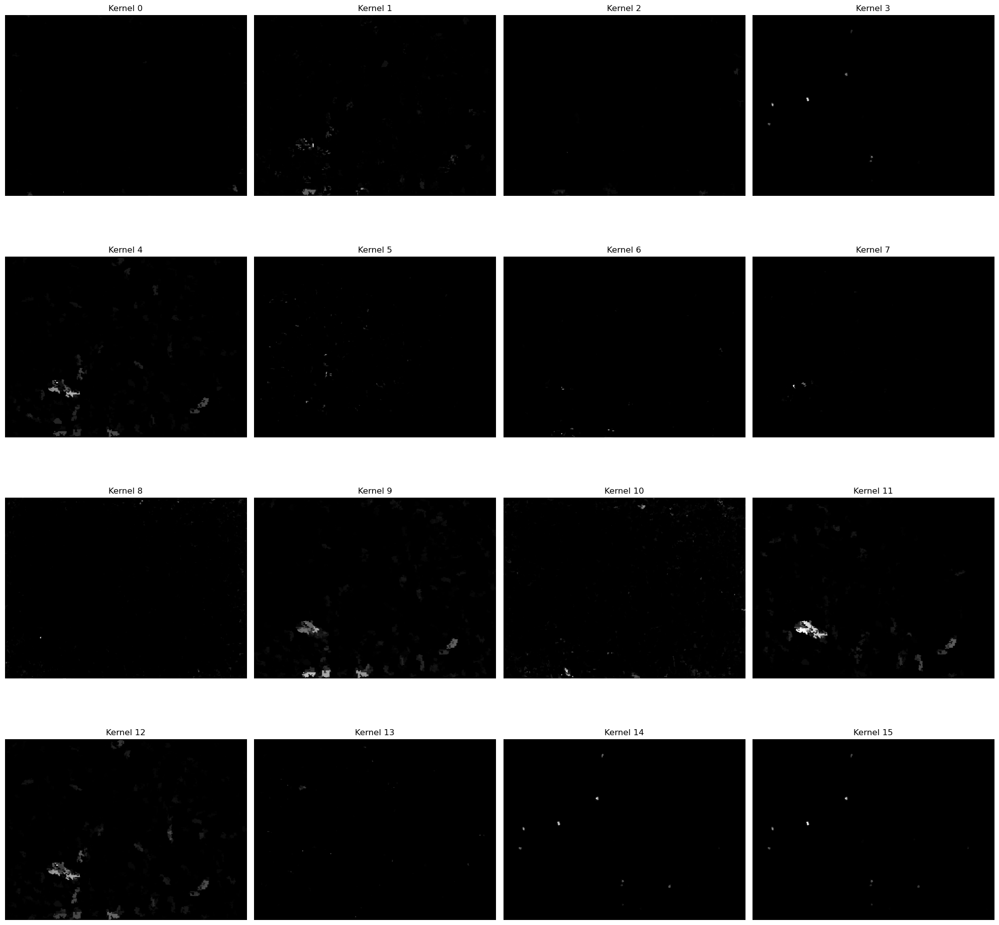

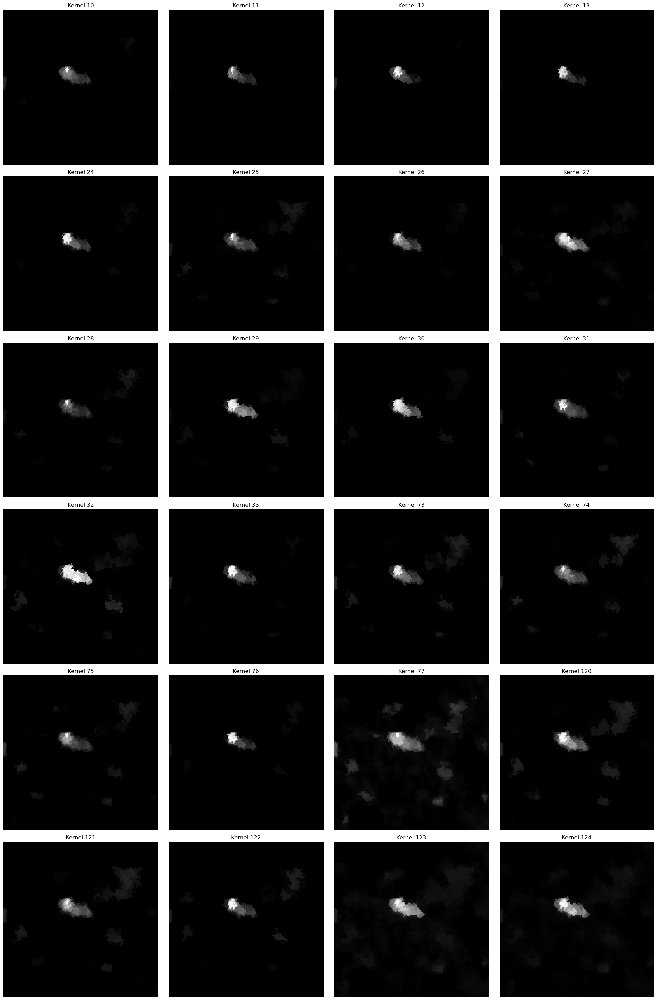




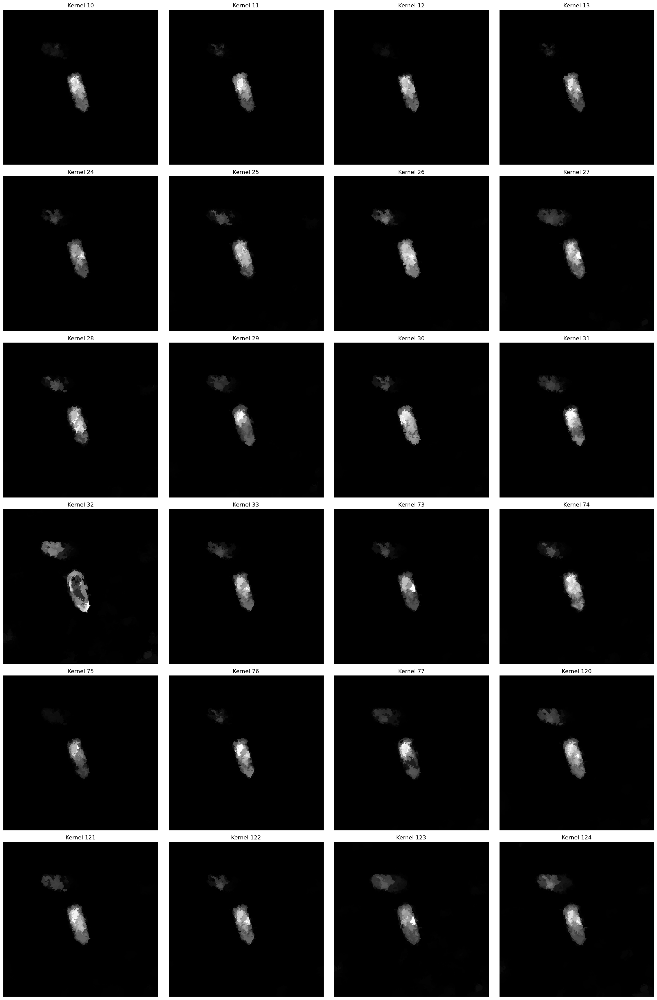




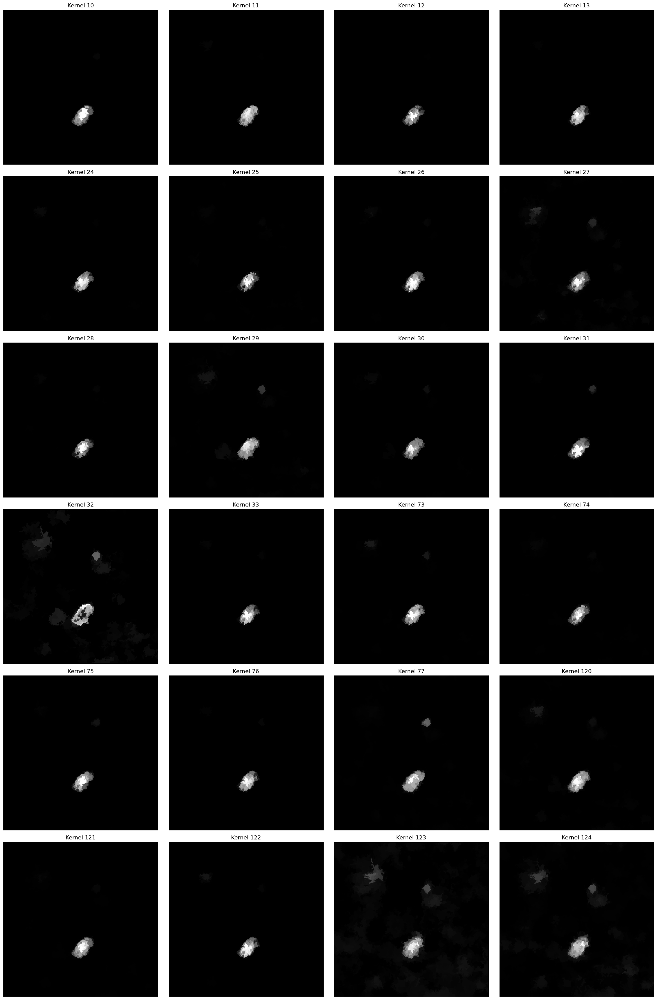




In [18]:
# merge scales using dot product and save results
for dataset in data['datasets']:
    for img_name in data[dataset]['img_names']:
        feature_matrices = [FeatureMatrix(np.array(fm)) for fm in data[dataset]['feature_matrices'][img_name]]
        feat_matrix = merge_scales_dotProd(feature_matrices, data[dataset]['node_maps'][img_name], data[dataset]['kernels_maps'], thresh=True, std=True)
        feat_matrix.visualize_activations(data[dataset]['spx_imgs'][img_name][0], data[dataset]['obj_kernels'], f'{dataset}_{img_name}_obj_kernels_merged_dotProd_thresh_std')
        feat_matrix.visualize_activations(data[dataset]['spx_imgs'][img_name][0], data[dataset]['bkg_kernels'], f'{dataset}_{img_name}_bkg_kernels_merged_dotProd_thresh_std')

In [ ]:
# merge scales using graph data directly

model_dir = '/home/isabela/Codes/LibIFT/Results/cells_dataset/split5/interactive_markers/arch_cells4/gflim-BoFP-multiscale/graph-based/SH/60000-40000-20000-10000/kmeans/SUM-NONE'
obj_kernels = [3,6,14,15]

for img_name in ['6', '10']:
    spx_scales = ['60000', '40000', '20000', '10000']
    # read graphs and superpixel images from different scales
    feature_matrices, spx_imgs = [], []
    for spx in spx_scales:
        path = os.path.join(model_dir, f'layer1_spx{spx}', f'{img_name}.json')
        graph = Graph(read_graph(path))
        graph.normalize_graph()
        feature_matrix = graph_to_featMatrix(graph)
        feature_matrix = FeatureMatrix(feature_matrix).normalize()
        feature_matrices.append(feature_matrix)
        path = os.path.join(model_dir, f'labels1_spx{spx}', f'{img_name}.pgm')
        spx_imgs.append(read_img(path, spx_img=True))

    num_kernels = feature_matrices[0].shape[1]
    bkg_kernels = [k for k in range(num_kernels) if k not in obj_kernels]

    # compute node size for each superpixel images
    #node_sizes = []
    #for spx_img in spx_imgs:
    #    node_size = np.array([len(spx_img[spx_img == p]) for p in range(1,spx_img.max())])
    #    node_sizes.append(node_size)

    # compute the node maps from a scale 0 to i+1
    node_maps = []
    spx_img0 = spx_imgs[0].flatten()
    nnodes0 = spx_img0.max()
    for i in range(1, len(spx_imgs)):
        spx_img1 = spx_imgs[i].flatten()
        node_map = np.zeros(nnodes0, dtype=int)
        for j,p in enumerate(spx_img0):
            node_map[p - 1] = int(spx_img1[j] - 1)
        node_maps.append(node_map)

    # contruct a kernels map from a scale 0 to i+1
    kernels_maps = []
    with open(os.path.join(model_dir, 'model', 'kernels_map_1.txt'), 'r') as f:
        for m,line in enumerate(f.readlines()):
            kernels = line.strip().split(' ')
            kernels_map = [i for i in range(len(kernels))] # store a mapping of kernels from scale 0 (finer) to i+1 (coarser)
            counter = 0 # count the kernel indexes of scale i+1 (coarser scale)
            for i,k in enumerate(kernels):
                k = int(k)-1
                if k != i:
                    k2 = kernels_map[k]
                    kernels_map[i] = k2           
                else:
                    kernels_map[i] = counter
                    counter += 1

            kernels_maps.append(kernels_map)

    # merge scales
    merged_features = merge_scales_sum(feature_matrices, node_maps, kernels_maps)

    """
    # visualize activations of each scale
    visualize_activations(spx_imgs[0], graphs[0], obj_kernels, f'{img_name}_activations_obj_60000spx')
    visualize_activations(spx_imgs[0], graphs[0], bkg_kernels, f'{img_name}_activations_bkg_60000spx')

    obj_kernels_i = set()
    for k in obj_kernels:
        obj_kernels_i.add(kernels_maps[0][k])
    visualize_activations(spx_imgs[1], graphs[1], obj_kernels_i, f'{img_name}_activations_obj_40000spx')

    bkg_kernels_i = [k for k in range(122) if k not in obj_kernels_i]
    visualize_activations(spx_imgs[1], graphs[1], bkg_kernels_i, f'{img_name}_activations_bkg_40000spx')

    obj_kernels_i = set()
    for k in obj_kernels:
        obj_kernels_i.add(kernels_maps[1][k])
    visualize_activations(spx_imgs[2], graphs[2], obj_kernels_i, f'{img_name}_activations_obj_20000spx')

    bkg_kernels_i = [k for k in range(112) if k not in obj_kernels_i]
    visualize_activations(spx_imgs[2], graphs[2], bkg_kernels_i, f'{img_name}_activations_bkg_20000spx')

    obj_kernels_i = set()
    for k in obj_kernels:
        obj_kernels_i.add(kernels_maps[1][k])
    visualize_activations(spx_imgs[2], graphs[2], obj_kernels_i, f'{img_name}_activations_obj_10000spx')

    bkg_kernels_i = [k for k in range(112) if k not in obj_kernels_i]
    visualize_activations(spx_imgs[2], graphs[2], bkg_kernels_i, f'{img_name}_activations_bkg_10000spx')
    """
    # visualize activations of the merged graph
    merged_features.visualize_activations(spx_imgs[0], obj_kernels, f'{img_name}_merged_sumNorm_obj_{"-".join([str(k) for k in spx_scales])}')
    merged_features.visualize_activations(spx_imgs[0], bkg_kernels, f'{img_name}_merged_sumNorm_bkg_{"-".join([str(k) for k in spx_scales])}')

In [ ]:
# merge scales using feature matrices

model_dir = '/home/isabela/Codes/LibIFT/Results/schisto/split1/interactive_markers/arch_schisto1/gflim-BoFP-multiscale/graph-based/SH/10000-8000-6000/kmeans/SUM-NONE/'
obj_kernels = [10,11,12,13,24,25,26,27,28,29,30,31,32,33,73,74,75,76,77,120,121,122,123,124]

for img_name in ['000028', '000017', '000212']:
    spx_scales = ['10000', '8000', '6000']
    # read graphs and superpixel images from different scales
    feature_matrices, spx_imgs = [], []
    for spx in spx_scales:
        path = os.path.join(model_dir, f'layer1_spx{spx}', f'{img_name}.json')
        graph = Graph(read_graph(path))
        graph.normalize_graph()
        feature_matrix = graph_to_featMatrix(graph)
        feature_matrix = FeatureMatrix(feature_matrix)#.normalize()
        feature_matrices.append(feature_matrix)
        path = os.path.join(model_dir, f'labels1_spx{spx}', f'{img_name}.pgm')
        spx_imgs.append(read_img(path, spx_img=True))

    num_kernels = feature_matrices[0].shape[1]
    bkg_kernels = [k for k in range(num_kernels) if k not in obj_kernels]

    # compute node size for each superpixel images
    #node_sizes = []
    #for spx_img in spx_imgs:
    #    node_size = np.array([len(spx_img[spx_img == p]) for p in range(1,spx_img.max())])
    #    node_sizes.append(node_size)

    # compute the node maps from a scale 0 to i+1
    node_maps = []
    spx_img0 = spx_imgs[0].flatten()
    nnodes0 = spx_img0.max()
    for i in range(1, len(spx_imgs)):
        spx_img1 = spx_imgs[i].flatten()
        node_map = np.zeros(nnodes0, dtype=int)
        for j,p in enumerate(spx_img0):
            node_map[p - 1] = int(spx_img1[j] - 1)
        node_maps.append(node_map)

    # contruct a kernels map from a scale 0 to i+1
    kernels_maps = []
    with open(os.path.join(model_dir, 'model', 'kernels_map_1.txt'), 'r') as f:
        for m,line in enumerate(f.readlines()):
            kernels = line.strip().split(' ')
            kernels_map = [i for i in range(len(kernels))] # store a mapping of kernels from scale 0 (finer) to i+1 (coarser)
            counter = 0 # count the kernel indexes of scale i+1 (coarser scale)
            for i,k in enumerate(kernels):
                k = int(k)-1
                if k != i:
                    k2 = kernels_map[k]
                    kernels_map[i] = k2           
                else:
                    kernels_map[i] = counter
                    counter += 1

            kernels_maps.append(kernels_map)

    # merge scales
    merged_features = merge_scales_sum(feature_matrices, node_maps, kernels_maps)

    """
    # visualize activations of each scale
    visualize_activations(spx_imgs[0], graphs[0], obj_kernels, f'{img_name}_activations_obj_10000spx')
    visualize_activations(spx_imgs[0], graphs[0], bkg_kernels, f'{img_name}_activations_bkg_10000spx')

    obj_kernels_i = set()
    for k in obj_kernels:
        obj_kernels_i.add(kernels_maps[0][k])
    visualize_activations(spx_imgs[1], graphs[1], obj_kernels_i, f'{img_name}_activations_obj_8000spx')

    bkg_kernels_i = [k for k in range(122) if k not in obj_kernels_i]
    visualize_activations(spx_imgs[1], graphs[1], bkg_kernels_i, f'{img_name}_activations_bkg_8000spx')

    obj_kernels_i = set()
    for k in obj_kernels:
        obj_kernels_i.add(kernels_maps[1][k])
    visualize_activations(spx_imgs[2], graphs[2], obj_kernels_i, f'{img_name}_activations_obj_6000spx')

    bkg_kernels_i = [k for k in range(112) if k not in obj_kernels_i]
    visualize_activations(spx_imgs[2], graphs[2], bkg_kernels_i, f'{img_name}_activations_bkg_6000spx')
    """
    # visualize activations of the merged graph
    merged_features.visualize_activations(spx_imgs[0], obj_kernels, f'{img_name}_merged_sumNorm_obj_{"-".join([str(k) for k in spx_scales])}')
    merged_features.visualize_activations(spx_imgs[0], bkg_kernels, f'{img_name}_merged_sumNorm_bkg_{"-".join([str(k) for k in spx_scales])}')

In [ ]:
# convert each feature channel of the merged graph into an image using the superpixel image of the first scale (10000)
spx_img = spx_imgs[0]
num_kernels = graphs[0]['num_feats']
kernels = [10,11,12,13,24,25,26,27,28,29,30,31,32,33,73,74,75,76,77,120,121,122,123,124]
num_kernels = len(kernels)

# visualize as a grid of images
ncols = 4
nrows = num_kernels // ncols + (num_kernels % ncols)
print(nrows, ncols, num_kernels)
fig, axes = plt.subplots(nrows, ncols, figsize=(5*ncols, 5*nrows))
for i,k in enumerate(kernels):

    # normalize values in the graph to [0,255]
    min_val, max_val = graphs[0][f'node{0}']['feats'][k], graphs[0][f'node{0}']['feats'][k]
    feats = np.zeros(graphs[0]['num_nodes'])
    for node_id in range(0,graphs[0]['num_nodes']):
        value = graphs[0][f'node{node_id}']['feats'][k]
        min_val = min(min_val, value)
        max_val = max(max_val, value)
        feats[node_id] = value
    feats = (feats - min_val) / (max_val - min_val) * 255

    feat_img = np.zeros((spx_img.shape[0] * spx_img.shape[1]))
    for j,p in enumerate(spx_imgs[0].flatten()):
        feat_img[j] = int(feats[p-1])

    feat_img = feat_img.reshape(spx_img.shape[0], spx_img.shape[1]).astype(np.uint8)
    # create color channels for feat_img
    feat_img = np.stack([feat_img, feat_img, feat_img], axis=-1)

    axes[i // ncols, i % ncols].imshow(feat_img)
    axes[i // ncols, i % ncols].set_title(f'Kernel {k}')
    axes[i // ncols, i % ncols].axis('off')
plt.tight_layout()
plt.show()

In [ ]:
# testando nodes_map: reconstruir the object activations a partir de spx_imgs[0], node_maps[0], e graphs[1]

# ...

# usando o spx_img diretamente
ch = 10
spx_img1 = spx_imgs[1].flatten()
graphi = copy.deepcopy(graphs[1])
act_img = np.zeros(spx_img1.shape)
for i,p in enumerate(spx_img1):
    act_img[i] = graphi[f'node{p-1}']['feats'][ch]  

max_val = np.max(act_img)
min_val = np.min(act_img)
act_img = (act_img - min_val) / (max_val - min_val) * 255

act_img = act_img.reshape(spx_imgs[1].shape[0], spx_imgs[1].shape[1]).astype(np.uint8)
act_img = np.stack([act_img, act_img, act_img], axis=-1)
plt.imshow(act_img)
plt.axis('off')
plt.show()

In [ ]:
# convert each feature channel of the merged graph into an image using the superpixel image of the first scale (10000)
spx_img = spx_imgs[0]
num_kernels = graphs[0]['num_feats']
kernels = [10,11,12,13,24,25,26,27,28,29,30,31,32,33,73,74,75,76,77,120,121,122,123,124]
num_kernels = len(kernels)

# visualize as a grid of images
ncols = 4
nrows = num_kernels // ncols + (num_kernels % ncols)
print(nrows, ncols, num_kernels)
fig, axes = plt.subplots(nrows, ncols, figsize=(5*ncols, 5*nrows))
for i,k in enumerate(kernels):

    # normalize values in the graph to [0,255]
    min_val, max_val = graphs[0][f'node{0}']['feats'][k], graphs[0][f'node{0}']['feats'][k]
    feats = np.zeros(graphs[0]['num_nodes'])
    for node_id in range(0,graphs[0]['num_nodes']):
        value = graphs[0][f'node{node_id}']['feats'][k]
        min_val = min(min_val, value)
        max_val = max(max_val, value)
        feats[node_id] = value
    feats = (feats - min_val) / (max_val - min_val) * 255

    feat_img = np.zeros((spx_img.shape[0] * spx_img.shape[1]))
    for j,p in enumerate(spx_imgs[0].flatten()):
        feat_img[j] = int(feats[p-1])

    feat_img = feat_img.reshape(spx_img.shape[0], spx_img.shape[1]).astype(np.uint8)
    # create color channels for feat_img
    feat_img = np.stack([feat_img, feat_img, feat_img], axis=-1)

    node_id = 3232
    feat_img[spx_img == node_id, 0] = 0
    feat_img[spx_img == node_id, 1] = 255
    feat_img[spx_img == node_id, 2] = 0

    axes[i // ncols, i % ncols].imshow(feat_img)
    axes[i // ncols, i % ncols].set_title(f'Kernel {k}')
    axes[i // ncols, i % ncols].axis('off')
plt.tight_layout()
plt.show()

In [ ]:
for node_id in range(merged_graph['num_nodes']):
    for i in range(merged_graph['num_feats']):
        val1 = graph_bkp[f'node{node_id}']['feats'][i]
        val2 = graphs[0][f'node{node_id}']['feats'][i]
        if val1 != val2:
            print(f"Node {node_id}, feature {i}: {val1} != {val2}")

In [ ]:
# merge scales with a dot product

# 1. Bottom-up merging maintaining the higher number of nodes (from 6000 to 10000)

# create a copy of graphs[0]
merged_graph = copy.deepcopy(graphs[0]) # start with the graph of the first scale (10000)

# make the merged graph empy
#for node_id in range(merged_graph['num_nodes']):
#    merged_graph[f'node{node_id}']['feats'] = [0.0 for _ in range(merged_graph['num_feats'])]

#thresh = compute_otsu_threshold(merged_graph)
#for i, t in enumerate(thresh):
#    merged_graph = sum_value(merged_graph, value=t, channel=i)
node_size_0 = node_sizes[0]
graph_0 = copy.deepcopy(graphs[0])
for scale in range(len(graphs) - 1):

    graph_i = copy.deepcopy(graphs[scale + 1]) # next scale graph
    node_map = node_maps[scale] # node map from a finer scale to a coarser scale
    kernel_map_i = kernels_maps[scale] # feature channels to merge
    node_size_i = node_sizes[scale + 1]
    
    # compute otsu threshold for the current graph
    #thresh = compute_otsu_threshold(graph_i)
    #for i, t in enumerate(thresh):
    #    graph_i = sum_value(graph_i, value=t, channel=i)

    nGroupedKernels = np.zeros(graph_i['num_feats'], dtype=float)
    for k in kernel_map_i:
        nGroupedKernels[k] += 1.0

    nnodes_zero = 0
    for node_id in range(merged_graph['num_nodes']):
        min_val, max_val = 0, 0
        node_i = node_map[node_id]
        #feats = np.zeros(merged_graph['num_feats'])
        feats_i = np.array(graph_i[f'node{node_i}']['feats'])
        feats_0 = np.array(graph_0[f'node{node_id}']['feats'])
        for i,k in enumerate(kernel_map_i):
            #feats[i] += (feats_0[i] / (feats_i[k] if feats_i[k] != 0 else 1e-6)) / nGroupedKernels[k]
            merged_graph[f'node{node_id}']['feats'][i] *= feats_i[k]

        #for i,k in enumerate(kernel_map_i):
        #    if merged_graph[f'node{node_id}']['feats'][i] < 0.12314412 and i in kernels:
        #        print(f"Scale {scale} to {scale+1}, Node {node_id}, kernel {i}: {merged_graph['node'+str(node_id)]['feats'][i]}")

        #merged_graph[f'node{node_id}']['feats'] += (feats)# * abs(node_size_i[node_i] - node_size_0[node_id]))
    
#for node_id in range(merged_graph['num_nodes']):
#    for i in range(merged_graph['num_feats']):
#        merged_graph[f'node{node_id}']['feats'][i] += (graphs[0][f'node{node_map[node_id]}']['feats'][i])


In [ ]:
n_diff_feat = 0
for node_id in range(merged_graph['num_nodes']):
    for i in range(merged_graph['num_feats']):
        val1 = graph_bkp[f'node{node_id}']['feats'][i]
        val2 = graphs[0][f'node{node_id}']['feats'][i]
        if val1 != val2:
            n_diff_feat += 1
            #print(f"Node {node_id}, feature {i}: {val1} != {val2}")
print(f'Number of different features: {n_diff_feat}')

In [ ]:
# convert each feature channel of the merged graph into an image using the superpixel image of the first scale (10000)
spx_img = spx_imgs[0]
num_kernels = merged_graph['num_feats']
kernels = [10,11,12,13,24,25,26,27,28,29,30,31,32,33,73,74,75,76,77,120,121,122,123,124]
num_kernels = len(kernels)

# visualize as a grid of images
ncols = 4
nrows = num_kernels // ncols + (num_kernels % ncols)
print(nrows, ncols, num_kernels)
fig, axes = plt.subplots(nrows, ncols, figsize=(5*ncols, 5*nrows))
for i,k in enumerate(kernels):
    max_val, min_val = 0, 0
    nnodes_positive = 0
    feats = np.zeros(merged_graph['num_nodes'])
    for node_id in range(merged_graph['num_nodes']):
        max_val = max(max_val, merged_graph[f'node{node_id}']['feats'][k])
        min_val = min(min_val, merged_graph[f'node{node_id}']['feats'][k])
    for node_id in range(merged_graph['num_nodes']):
        feats[node_id] = merged_graph[f'node{node_id}']['feats'][k] / max_val * 255
        if merged_graph[f'node{node_id}']['feats'][k] > 0:
            nnodes_positive += 1
    #    feats[node_id] = (merged_graph[f'node{node_id}']['feats'][k] - min_val) / (max_val - min_val) * 255

    feat_img = np.zeros((spx_img.shape[0] * spx_img.shape[1]))
    for j,p in enumerate(spx_imgs[0].flatten()):
        feat_img[j] = int(feats[p-1])

    feat_img = feat_img.reshape(spx_img.shape[0], spx_img.shape[1]).astype(np.uint8)

    # save feat_img as a png
    Image.fromarray(feat_img).save(f'/home/isabela/Codes/kernel_{k}_merged.png')

    axes[i // ncols, i % ncols].imshow(feat_img, cmap='gray')
    axes[i // ncols, i % ncols].set_title(f'Kernel {k}')
    axes[i // ncols, i % ncols].axis('off')
plt.tight_layout()
plt.show()

In [ ]:
# convert each feature channel of the merged graph into an image using the superpixel image of the first scale (10000)
spx_img = spx_imgs[0]
num_kernels = merged_graph['num_feats']
kernels = [0,1,2,3,4,5,6,7,8,9,14,15,16,17,18,19,
           20,21,22,23,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,
           50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,
           70,71,72,78,79,80,81,82,83,84,85,86,87,88,89,90,91,92,93,94,95,96,97,98,99,
           100,101,102,103,104,105,106,107,108,109,
           110,111,112,113,114,115,116,117,118,119,125,126,127,128,129,
           130,131,132,133,134,135,136]
num_kernels = len(kernels)

# visualize as a grid of images
ncols = 4
nrows = num_kernels // ncols + (num_kernels % ncols)
print(nrows, ncols, num_kernels)
fig, axes = plt.subplots(nrows, ncols, figsize=(5*ncols, 5*nrows))
for i,k in enumerate(kernels):
    max_val, min_val = 0, 0
    nnodes_positive = 0
    feats = np.zeros(merged_graph['num_nodes'])
    for node_id in range(merged_graph['num_nodes']):
        max_val = max(max_val, merged_graph[f'node{node_id}']['feats'][k])
        min_val = min(min_val, merged_graph[f'node{node_id}']['feats'][k])
    for node_id in range(merged_graph['num_nodes']):
        feats[node_id] = merged_graph[f'node{node_id}']['feats'][k] / max_val * 255
        
    feat_img = np.zeros((spx_img.shape[0] * spx_img.shape[1]))
    for j,p in enumerate(spx_imgs[0].flatten()):
        feat_img[j] = int(feats[p-1])

    feat_img = feat_img.reshape(spx_img.shape[0], spx_img.shape[1]).astype(np.uint8)

    # save feat_img as a png
    Image.fromarray(feat_img).save(f'/home/isabela/Codes/kernel_{k}_merged_bkg.png')

    axes[i // ncols, i % ncols].imshow(feat_img, cmap='gray')
    axes[i // ncols, i % ncols].set_title(f'Kernel {k}')
    axes[i // ncols, i % ncols].axis('off')
plt.tight_layout()
plt.show()